In [1]:
# conda env 'vis2'
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent.parent
V = 'V04'
VERSION = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / V
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'
FIGURE_OUT = PROJECT_ROOT / 'figures'

import sys
import os
sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import glob
import at3d

savefigs = True
fig_version = 'V03'

In [2]:
def segment_cloud(cloud, cvm):
    cloud['volume'] = cloud.extinction > 0
    cloud['volume'].data = cloud['volume'].data.astype(np.int64)
    cloud['cth_cloud'] = cloud.volume & cvm.cth_cloud
    cloud['lcl_cloud'] = cloud.volume & cvm.lcl_cloud
    cloud['spc_cloud'] = cloud.volume & cvm.spc_cloud
    cloud['cth_clear'] = cloud.volume & cvm.cth_clear
    cloud['lcl_clear'] = cloud.volume & cvm.lcl_clear
    cloud['spc_clear'] = cloud.volume & cvm.spc_clear
    cloud['cloud'] = cloud.volume & cvm.cloud
    cloud['clear'] = cloud.volume & cvm.clear
    cloud['intersection'] = cloud.cth_cloud & cloud.lcl_cloud & cloud.spc_cloud & cloud.cth_clear & cloud.lcl_clear & cloud.spc_clear & cloud.cloud & cloud.clear
    cloud['union'] = cloud.cth_cloud | cloud.lcl_cloud | cloud.spc_cloud | cloud.cth_clear | cloud.lcl_clear | cloud.spc_clear | cloud.cloud | cloud.clear
    return cloud

def load_cvm(filename):
    cvm = xr.load_dataset(filename)
    cvm['lcl_mask'].data = cvm['lcl_mask'].data.astype(np.int64)
    cvm['cloud_volume_mask'].data = cvm['cloud_volume_mask'].data.astype(np.int64)
    cvm['cth_mask'].data[0,:,:] = cvm['cth_mask'].data[-1,:,:] = 0
    cvm['cth_mask'].data[:,0,:] = cvm['cth_mask'].data[:,-1,:] = 0
    cvm['lcl_mask'].data[0,:,:] = cvm['lcl_mask'].data[-1,:,:] = 0
    cvm['lcl_mask'].data[:,0,:] = cvm['lcl_mask'].data[:,-1,:] = 0
    cvm['sc_mask'].data[0,:,:] = cvm['sc_mask'].data[-1,:,:] = 0
    cvm['sc_mask'].data[:,0,:] = cvm['sc_mask'].data[:,-1,:] = 0
    cvm['cloud_volume_mask'].data[0,:,:] = cvm['cloud_volume_mask'].data[-1,:,:] = 0
    cvm['cloud_volume_mask'].data[:,0,:] = cvm['cloud_volume_mask'].data[:,-1,:] = 0

    cvm['cth_cloud'] = cvm.cth_mask & np.logical_not(cvm.lcl_mask) & np.logical_not(cvm.sc_mask)
    cvm['lcl_cloud'] = np.logical_not(cvm.cth_mask) & cvm.lcl_mask & np.logical_not(cvm.sc_mask)
    cvm['spc_cloud'] = np.logical_not(cvm.cth_mask) & np.logical_not(cvm.lcl_mask) & cvm.sc_mask
    cvm['cth_clear'] = np.logical_not(cvm.cth_mask) & cvm.lcl_mask & cvm.sc_mask
    cvm['lcl_clear'] = cvm.cth_mask & np.logical_not(cvm.lcl_mask) & cvm.sc_mask
    cvm['spc_clear'] = cvm.cth_mask & cvm.lcl_mask & np.logical_not(cvm.sc_mask)
    cvm['cloud'] = cvm.cth_mask & cvm.lcl_mask & cvm.sc_mask
    cvm['clear'] = np.logical_not(cvm.cth_mask) & np.logical_not(cvm.lcl_mask) & np.logical_not(cvm.sc_mask)
    cvm['clear'].data = cvm['clear'].data.astype(np.int64)
    cvm['intersection'] = cvm.cth_cloud & cvm.lcl_cloud & cvm.spc_cloud & cvm.cth_clear & cvm.lcl_clear & cvm.spc_clear & cvm.cloud & cvm.clear
    cvm['union'] = cvm.cth_cloud | cvm.lcl_cloud | cvm.spc_cloud | cvm.cth_clear | cvm.lcl_clear | cvm.spc_clear | cvm.cloud | cvm.clear
    return cvm

def set_labels(ax_flat):
    labels = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)', 'i)']
    for i, a in enumerate(ax_flat):
        a.set_title(
            labels[i],
            fontfamily='serif',
            loc='left',
            fontsize='medium',
            fontweight='bold'
        )


In [ ]:
CVM_file_def = INTERIM_DATA / 'CVM_CAMP2Ex_RF17_default_open.nc'

cvm_def = load_cvm(CVM_file_def)

In [ ]:
titles = [
    'slow unconstrained',
    'unconstrained',
    'fast unconstrained'
]

iter_files = [
    VERSION / 'cloud_motion' / 'slow_unconstrained' / 'iterations',
    VERSION / 'CVM' / 'unconstrained' / 'iterations',
    VERSION / 'cloud_motion' / 'fast_unconstrained_restart' / 'iterations'
]

cvms = [
    cvm_def,
    cvm_def,
    cvm_def
]

clouds = {}
for title, iter_file, cvm in zip(titles, iter_files, cvms):
    files = sorted(iter_file.glob('iter*.nc'))
    sensors, solvers, rte_grid = at3d.util.load_forward_model(files[-1])
    cloud = solvers[0.67].medium['cloud']
    cloud = segment_cloud(cloud, cvm)
    clouds[title] = cloud

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '31'. Max cell optical depth: '3.5379703044891357'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3

In [5]:
regions = ['cth_cloud', 'lcl_cloud', 'spc_cloud', 'cth_clear', 'lcl_clear', 'spc_clear', 'cloud', 'clear']
print('Cloud Volume By Region (pct of total)')
tmp = '{:<10} |'.format('Region')
for t in titles:
    tmp += ' {:<19} |'.format(t)
tmp += ' {:<20}'.format('CVM Volume')
print(tmp)
print('-'*(len(titles)*21 + 12 + 22))
for r in regions:
    tmp = '{:<10} |'.format(r)
    for t in titles:
        c = clouds[t]
        rvol = c[r].integrate(['x','y','z']).data
        tot_vol = c.volume.integrate(['x','y','z']).data
        tmp += ' {:<8.3f} ({:<7.2f}%) |'.format(rvol, 100*rvol/tot_vol)
    tmp += ' {:<20.3f}'.format(cvm[r].integrate(['x','y','z']).data)
    print(tmp)
print('-'*(len(titles)*21 + 12 + 22))
tmp = '{:<10} |'.format('TOTAL')
for t in titles:
    c = clouds[t]
    rvol = c[r].integrate(['x','y','z']).data
    tot_vol = c.volume.integrate(['x','y','z']).data
    tmp += ' {:<19.3f} |'.format(tot_vol)
tmp += ' {:<20.3f}'.format(cvm.union.integrate(['x','y','z']).data)
print(tmp)

Cloud Volume By Region (pct of total)
Region     | slow unconstrained  | unconstrained       | fast unconstrained  | CVM Volume          
-------------------------------------------------------------------------------------------------
cth_cloud  | 0.015    (0.03   %) | 0.000    (0.00   %) | 0.000    (0.00   %) | 12.210              
lcl_cloud  | 0.023    (0.04   %) | 0.011    (0.02   %) | 0.015    (0.03   %) | 22.298              
spc_cloud  | 0.000    (0.00   %) | 0.000    (0.00   %) | 0.000    (0.00   %) | 0.000               
cth_clear  | 32.814   (57.25  %) | 27.327   (50.38  %) | 28.628   (47.70  %) | 193.328             
lcl_clear  | 7.581    (13.23  %) | 7.895    (14.55  %) | 12.478   (20.79  %) | 92.716              
spc_clear  | 0.000    (0.00   %) | 0.000    (0.00   %) | 0.000    (0.00   %) | 11.374              
cloud      | 16.880   (29.45  %) | 19.012   (35.05  %) | 18.899   (31.49  %) | 88.164              
clear      | 0.000    (0.00   %) | 0.000    (0.00   %) | 0.000  

In [6]:
# ## Relative Bias and Difference from WITHIN the CVM
# cond = cvm.cloud_volume_mask.data == 1
# ext_def = cloud_def.extinction.data[cond]
# ext_unc = cloud_unc.extinction.data[cond]
# rel_diff = 100 * (np.sum((ext_unc - ext_def)**2))**0.5 / (np.sum(ext_def)**2)**0.5
# rel_bias = 100 * (np.sum(np.abs(ext_unc)) - np.sum(np.abs(ext_def))) / (np.sum(np.abs(ext_def)))

# print('Relative Bias: {:.2f}'.format(rel_bias))
# print('Relative Diff: {:.2f}'.format(rel_diff))

## Figure 17: Cloud Motion Unconstrained

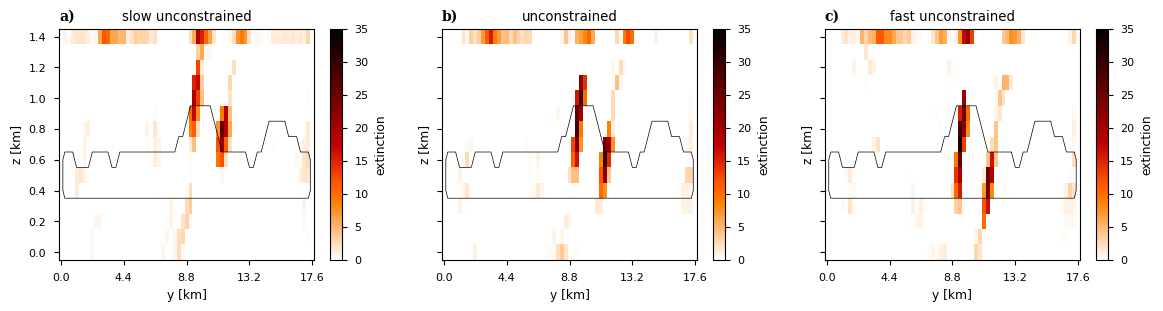

In [7]:
ext_cmap = 'gist_heat_r'
x = 10.18
vmax = 35
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
plt.style.use('default')
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
clouds[titles[0]].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[0], vmin=0, vmax=vmax, cmap=ext_cmap)
clouds[titles[1]].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[1], vmin=0, vmax=vmax, cmap=ext_cmap)
clouds[titles[2]].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[2], vmin=0, vmax=vmax, cmap=ext_cmap)
cvms[0].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[0], colors='black', linewidths=0.5, linestyles='solid')
cvms[1].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[1], colors='black', linewidths=0.5, linestyles='solid')
cvms[2].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[2], colors='black', linewidths=0.5, linestyles='solid')

ax[0].set_title(titles[0])
ax[1].set_title(titles[1])
ax[2].set_title(titles[2])

for a in ax:
    a.set_xticks(ticks)
    a.set_xlabel('y [km]')
    a.set_ylabel('z [km]')

set_labels(ax.flatten())

if(savefigs):
    plt.savefig(
        FIGURE_OUT / '{}_figure17_cloud_motion_unc.png'.format(fig_version),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )

In [8]:
# ext_cmap = 'gist_heat_r'
# xs = np.arange(0, 17.6, 1.1) + 0.275
# vmax = 35
# plt.style.use('default')
# plt.style.use('seaborn-v0_8-paper')
# f, ax = plt.subplots(len(xs), 3, figsize=(14, 3*len(xs)), sharey=True)
# for i, x in enumerate(xs):
#     clouds[titles[0]].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[i, 0], vmin=0, vmax=vmax, cmap=ext_cmap)
#     clouds[titles[1]].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[i, 1], vmin=0, vmax=vmax, cmap=ext_cmap)
#     clouds[titles[2]].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[i, 2], vmin=0, vmax=vmax, cmap=ext_cmap)
#     cvms[0].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 0], colors='black', linewidths=0.5, linestyles='dashed')
#     cvms[1].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 1], colors='black', linewidths=0.5, linestyles='solid')
#     cvms[2].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 2], colors='black', linewidths=0.5, linestyles='dashed')

# ax[0, 0].set_title(titles[0])
# ax[0, 1].set_title(titles[1])
# ax[0, 2].set_title(titles[2])

In [9]:
# ext_cmap = 'gist_heat_r'
# x = 1.375
# vmax = 35
# rng = 20
# plt.style.use('default')
# plt.style.use('seaborn-v0_8-paper')
# f, ax = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
# (clouds[titles[0]].extinction - clouds[titles[1]].extinction).sel(x=x, method='nearest').plot(y='z', ax=ax[0], vmin=-rng, vmax=rng, cmap='RdBu_r')
# clouds[titles[1]].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[1], vmin=0, vmax=vmax, cmap=ext_cmap)
# (clouds[titles[2]].extinction - clouds[titles[1]].extinction).sel(x=x, method='nearest').plot(y='z', ax=ax[2], vmin=-rng, vmax=rng, cmap='RdBu_r')
# cvms[0].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[0], colors='black', linewidths=0.5, linestyles='dashed')
# cvms[1].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[1], colors='black', linewidths=0.5, linestyles='solid')
# cvms[2].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[2], colors='black', linewidths=0.5, linestyles='dashed')

# ax[0].set_title(titles[0])
# ax[1].set_title(titles[1])
# ax[2].set_title(titles[2])

In [10]:
# ext_cmap = 'gist_heat_r'
# xs = np.arange(0, 17.6, 1.1) + 0.275*2
# vmax = 35
# rng = 20
# plt.style.use('default')
# plt.style.use('seaborn-v0_8-paper')
# f, ax = plt.subplots(len(xs), 3, figsize=(14, 3*len(xs)), sharey=True)
# for i, x in enumerate(xs):
#     (clouds[titles[0]].extinction - clouds[titles[1]].extinction).sel(x=x, method='nearest').plot(y='z', ax=ax[i, 0], vmin=-rng, vmax=rng, cmap='RdBu_r')
#     clouds[titles[1]].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[i, 1], vmin=0, vmax=vmax, cmap=ext_cmap)
#     (clouds[titles[2]].extinction - clouds[titles[1]].extinction).sel(x=x, method='nearest').plot(y='z', ax=ax[i, 2], vmin=-rng, vmax=rng, cmap='RdBu_r')
#     cvms[0].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 0], colors='black', linewidths=0.5, linestyles='dashed')
#     cvms[1].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 1], colors='black', linewidths=0.5, linestyles='solid')
#     cvms[2].sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 2], colors='black', linewidths=0.5, linestyles='dashed')

# ax[0, 0].set_title(titles[0])
# ax[0, 1].set_title(titles[1])
# ax[0, 2].set_title(titles[2])